# Stage 2 — Customer Churn Dataset & Exploratory Data Analysis

**Project:** Customer Churn Prediction + Explainable AI  
**Stage:** 2 — Data Exploration & Quality Analysis  

### Objectives for Stage 2:
1. **Load and inspect** the IBM Telco Customer Churn dataset.
2. **Verify data quality**, identifying missing values, empty string placeholders, duplicate records, and data type discrepancies.
3. **Analyze the target variable (`Churn`)** to quantify class distribution and understand class imbalance.
4. **Perform Exploratory Data Analysis (EDA)** addressing key business questions regarding customer tenure, charges, contract types, payment methods, and service add-ons.
5. **Extract actionable business insights** distinguishing observations, possible explanations, and strategic business implications.
6. **Categorize features** into numerical, categorical, and unnecessary groups for upcoming model building.

## Part 1 & 2: Environment Setup & Data Loading

We start by importing the foundational data analysis and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`). We then load `data/telco_customer_churn.csv` using Pandas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall style and figure defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('crest')
pd.set_option('display.max_columns', None)

# Load dataset from data directory
dataset_path = '../data/telco_customer_churn.csv'
df = pd.read_csv(dataset_path)
print('Dataset loaded successfully!')

Dataset loaded successfully!


In [2]:
print(f'Dataset Dimensions: {df.shape[0]} rows and {df.shape[1]} columns\n')
print('--- First 5 Rows ---')
display(df.head())
print('\n--- Last 5 Rows ---')
display(df.tail())

Dataset Dimensions: 7043 rows and 21 columns

--- First 5 Rows ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Last 5 Rows ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [3]:
print('--- Dataset Info & Data Types ---')
df.info()

--- Dataset Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperles

### Initial Observation on Data Types:
- **Numerical Columns:** `SeniorCitizen` (int64), `tenure` (int64), `MonthlyCharges` (float64).
- **Categorical Columns:** `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `Churn`.
- **Anomaly Detected (`TotalCharges`):** `TotalCharges` is stored as an `object` (string) rather than a floating-point numerical column. This requires investigation during our data quality checks.
- **ID Column:** `customerID` (unique alphanumeric string).
- **Target Column:** `Churn` (`Yes` / `No` text string).

## Part 3: Understanding Every Important Column

Understanding the business domain context for each column is essential before building machine learning models.

| Column Name | Category | Data Type | Business Meaning | Potential ML Role |
| :--- | :--- | :--- | :--- | :--- |
| `customerID` | Identifier | String (Object) | Unique alphanumeric code for each customer | **Exclude** — Pure identifier; causes overfitting. |
| `gender` | Demographic | String (Object) | Male or Female | **Include** — Demographic baseline feature. |
| `SeniorCitizen` | Demographic | Binary (0/1) | Whether customer is 65 years or older | **Include** — Demographic feature for age group behaviors. |
| `Partner` | Demographic | String (Object) | Whether customer has a partner | **Include** — Household stability indicator. |
| `Dependents` | Demographic | String (Object) | Whether customer has financial dependents | **Include** — Family/household commitment indicator. |
| `tenure` | Relationship | Integer (Months) | Months customer has stayed with company | **Include** — Major predictor of loyalty and retention. |
| `PhoneService` | Core Service | String (Object) | Voice phone subscription status | **Include** — Core telecommunication service feature. |
| `MultipleLines` | Core Service | String (Object) | Multiple phone lines status | **Include** — Tiered voice service add-on. |
| `InternetService` | Core Service | String (Object) | DSL, Fiber optic, or No internet | **Include** — Critical service line feature. |
| `OnlineSecurity` | Add-on Service | String (Object) | Cybersecurity protection add-on | **Include** — Value-added safety service. |
| `OnlineBackup` | Add-on Service | String (Object) | Cloud data backup add-on | **Include** — Value-added storage service. |
| `DeviceProtection` | Add-on Service | String (Object) | Tech hardware protection plan | **Include** — Value-added hardware coverage. |
| `TechSupport` | Add-on Service | String (Object) | Premium technical assistance | **Include** — Critical customer support add-on. |
| `StreamingTV` | Add-on Service | String (Object) | IP-based TV streaming option | **Include** — Entertainment content feature. |
| `StreamingMovies` | Add-on Service | String (Object) | IP-based movie streaming option | **Include** — Entertainment content feature. |
| `Contract` | Agreement | String (Object) | Month-to-month, One year, Two year | **Include** — Primary predictor of customer commitment. |
| `PaperlessBilling` | Financial | String (Object) | Digital vs paper billing preference | **Include** — Behavioral digital preference feature. |
| `PaymentMethod` | Financial | String (Object) | Electronic check, Mailed check, Bank/Card | **Include** — Payment channel indicator. |
| `MonthlyCharges` | Financial | Float ($) | Current monthly billed amount | **Include** — Primary cost feature. |
| `TotalCharges` | Financial | String ($ object) | Cumulative charges across entire tenure | **Include** — Lifetime account monetary value (needs numeric conversion). |
| `Churn` | Target | String (Yes/No) | Customer churn status in the last month | **Target Label** — Ground truth variable to predict. |

> **Correlation vs. Causation Warning:** High correlation between a feature (e.g., `Month-to-month` contract) and `Churn` does not guarantee that the contract type itself causes churn; rather, it indicates an association that can be used for predictive modeling.

## Part 4: Data Quality Checks

We perform rigorous checks for standard missing values (`NaN`), hidden empty strings / blank spaces, duplicate records, and invalid data types.

In [4]:
print('=== Standard Missing Values (NaN) Check ===')
print(df.isnull().sum())

print('\n=== Empty String / Blank Space Check across Object Columns ===')
blank_summary = {}
for col in df.select_dtypes(include='object').columns:
    blank_count = (df[col].astype(str).str.strip() == '').sum()
    if blank_count > 0:
        blank_summary[col] = blank_count
        print(f"⚠️ Column '{col}' contains {blank_count} empty/whitespace string entries!")

if not blank_summary:
    print('No empty whitespace strings found in object columns.')

=== Standard Missing Values (NaN) Check ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

=== Empty String / Blank Space Check across Object Columns ===
⚠️ Column 'TotalCharges' contains 11 empty/whitespace string entries!


In [5]:
print('=== Inspecting Records with Blank TotalCharges ===')
blank_total_charges_df = df[df['TotalCharges'].astype(str).str.strip() == '']
print(f'Total blank records found in TotalCharges: {len(blank_total_charges_df)}')
display(blank_total_charges_df[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'Churn']])

=== Inspecting Records with Blank TotalCharges ===
Total blank records found in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [6]:
print('=== Duplicate Records & Identifier Uniqueness Checks ===')
print(f'Duplicate rows in dataset: {df.duplicated().sum()}')
print(f'Total rows: {len(df)}')
print(f'Unique customerIDs: {df["customerID"].nunique()}')
print(f'Are all customerIDs unique? {df["customerID"].nunique() == len(df)}')

=== Duplicate Records & Identifier Uniqueness Checks ===
Duplicate rows in dataset: 0
Total rows: 7043
Unique customerIDs: 7043
Are all customerIDs unique? True


### Summary of Data Quality Findings:
1. **Missing Values (`NaN`):** `0` explicit `NaN` values across all columns.
2. **Whitespace Issues:** Exactly **11 rows** in `TotalCharges` contain blank spaces (`" "`). These 11 records correspond to brand new customers with `tenure == 0` months who have not completed their first billing cycle.
3. **Duplicate Rows:** `0` duplicate rows found.
4. **Customer Identifier:** All `7,043` `customerID` values are 100% unique.
5. **Data Type Anomaly:** `TotalCharges` is stored as an `object` string due to the 11 blank spaces. In later pipeline stages, these blank strings should be imputed (e.g., set to `0.0`) and converted to `float64`.

## Part 5: Understand the Target Variable (`Churn`)

The target variable `Churn` indicates whether a customer left the telecommunication company in the previous month (`Yes` vs `No`).

=== Target Variable Distribution ===


,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\450071183.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Churn', palette=['#2ca02c', '#d62728'], ax=ax[0])


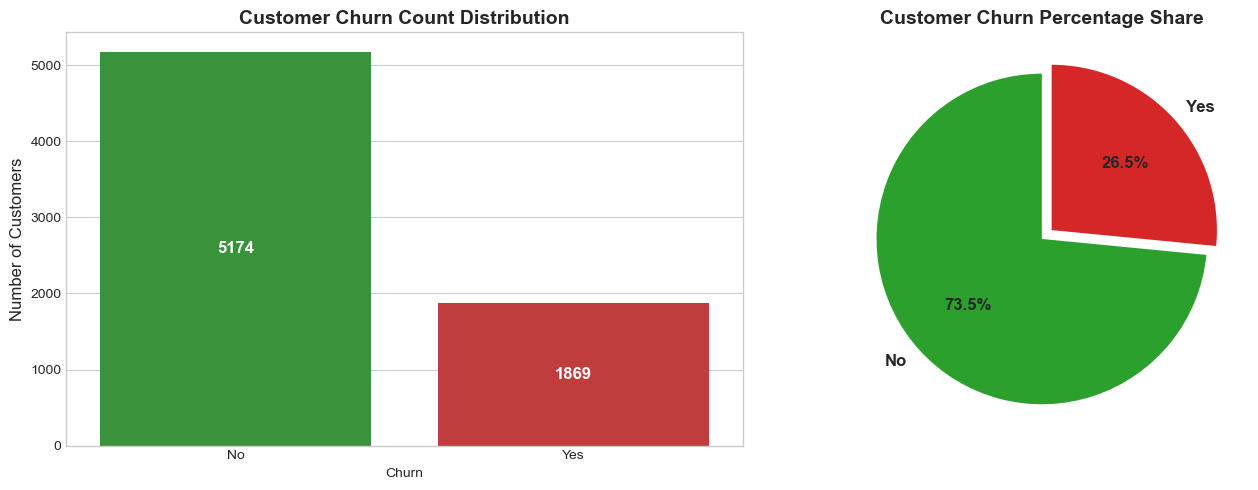

In [7]:
churn_counts = df['Churn'].value_counts()
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

print('=== Target Variable Distribution ===')
target_df = pd.DataFrame({
    'Count': churn_counts,
    'Percentage (%)': churn_percentages.round(2)
})
display(target_df)

# Visualization of Target Variable
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count Plot
sns.countplot(data=df, x='Churn', palette=['#2ca02c', '#d62728'], ax=ax[0])
ax[0].set_title('Customer Churn Count Distribution', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Number of Customers', fontsize=12)
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Donut / Pie Chart
ax[1].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%', explode=[0, 0.08],
          colors=['#2ca02c', '#d62728'], startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
ax[1].set_title('Customer Churn Percentage Share', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### Importance of Class Imbalance in Churn Prediction:
- **Distribution:** 5,174 customers (`73.46%`) retained (`No`) vs. 1,869 customers (`26.54%`) churned (`Yes`).
- **Imbalance Impact:** This represents a moderate class imbalance (~3:1 ratio).
- **Evaluation Implications:** If a naive classifier blindly predicts `No` for every customer, it would achieve **73.46% accuracy** while failing to detect 100% of churned customers. Therefore, raw accuracy is a misleading metric for churn modeling.
- **Required Metrics for Model Building:** We must evaluate models using Precision, Recall, F1-Score, PR-AUC, and ROC-AUC, prioritizing high Recall to identify at-risk customers early.

## Part 6: Exploratory Data Analysis (EDA)

We investigate 8 key business questions regarding customer characteristics and their relationship with customer churn.

### Question 1: Does customer tenure appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\2110823071.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette=['#2ca02c', '#d62728'], ax=ax[1])


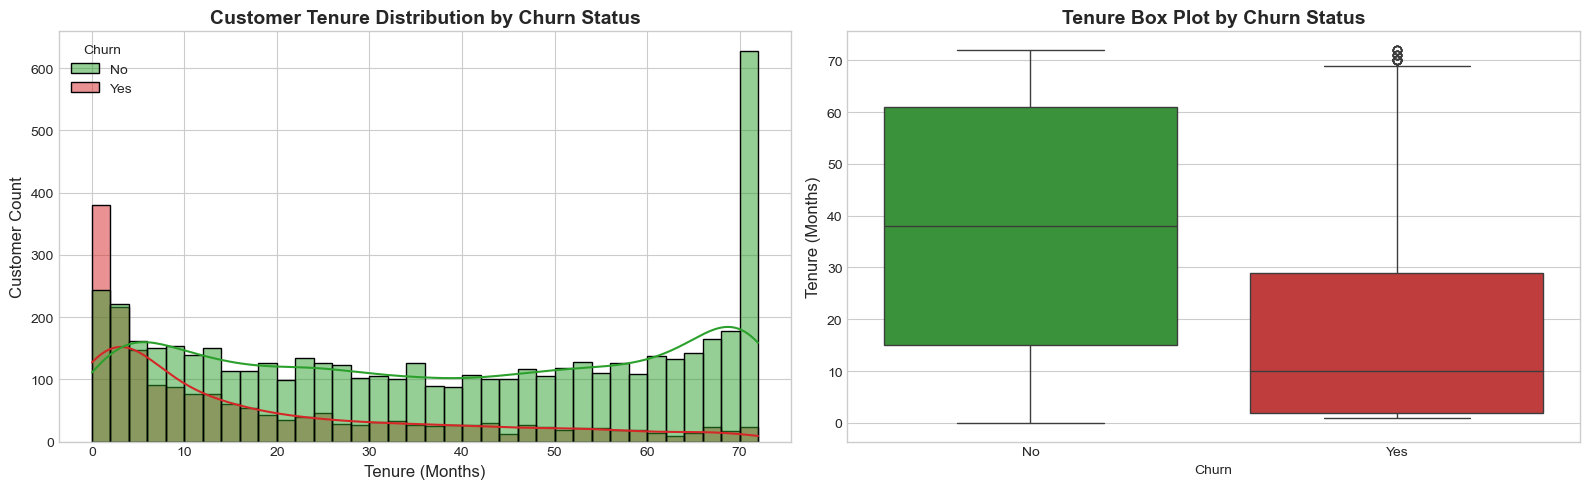

Tenure summary by Churn status:


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Histplot with KDE
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, palette=['#2ca02c', '#d62728'], bins=36, ax=ax[0])
ax[0].set_title('Customer Tenure Distribution by Churn Status', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Tenure (Months)', fontsize=12)
ax[0].set_ylabel('Customer Count', fontsize=12)

# Boxplot
sns.boxplot(data=df, x='Churn', y='tenure', palette=['#2ca02c', '#d62728'], ax=ax[1])
ax[1].set_title('Tenure Box Plot by Churn Status', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Tenure (Months)', fontsize=12)

plt.tight_layout()
plt.show()

print('Tenure summary by Churn status:')
display(df.groupby('Churn')['tenure'].describe())

### Question 2: Does monthly charge appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\4294904365.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2ca02c', '#d62728'], ax=ax[1])


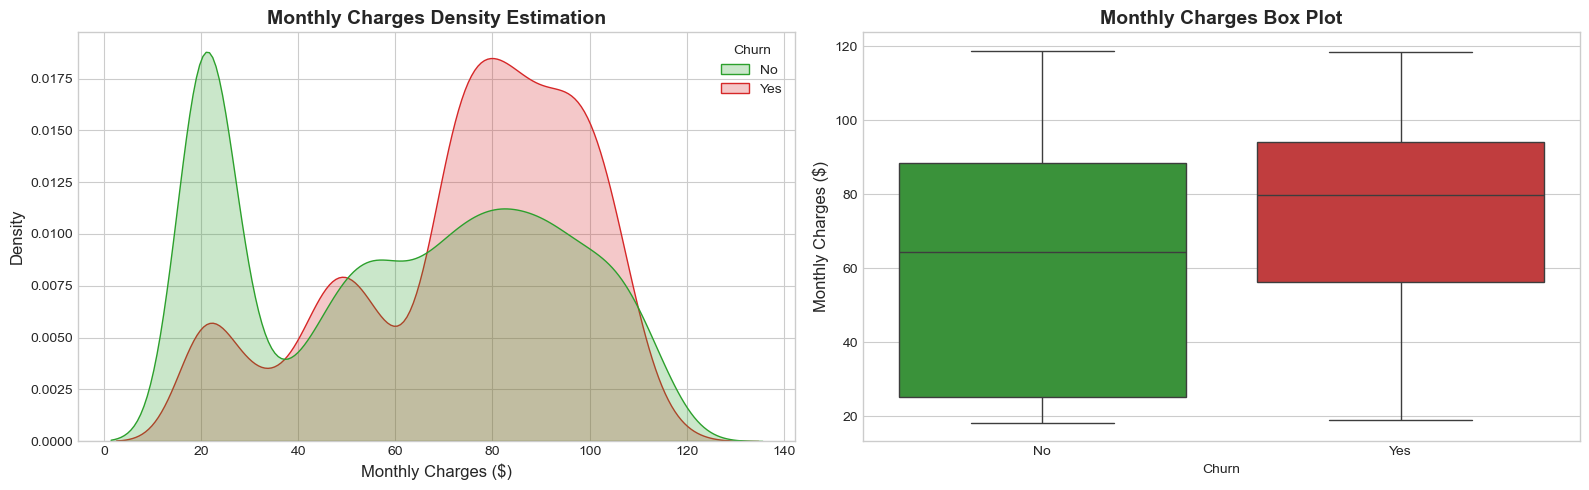

Monthly Charges summary by Churn status:


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# KDE Plot
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, fill=True, palette=['#2ca02c', '#d62728'], ax=ax[0])
ax[0].set_title('Monthly Charges Density Estimation', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Monthly Charges ($)', fontsize=12)
ax[0].set_ylabel('Density', fontsize=12)

# Boxplot
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2ca02c', '#d62728'], ax=ax[1])
ax[1].set_title('Monthly Charges Box Plot', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Monthly Charges ($)', fontsize=12)

plt.tight_layout()
plt.show()

print('Monthly Charges summary by Churn status:')
display(df.groupby('Churn')['MonthlyCharges'].describe())

### Question 3: Does contract type appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\1748998206.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x='Contract', y='Churn', palette='Reds_d', ax=ax[1])


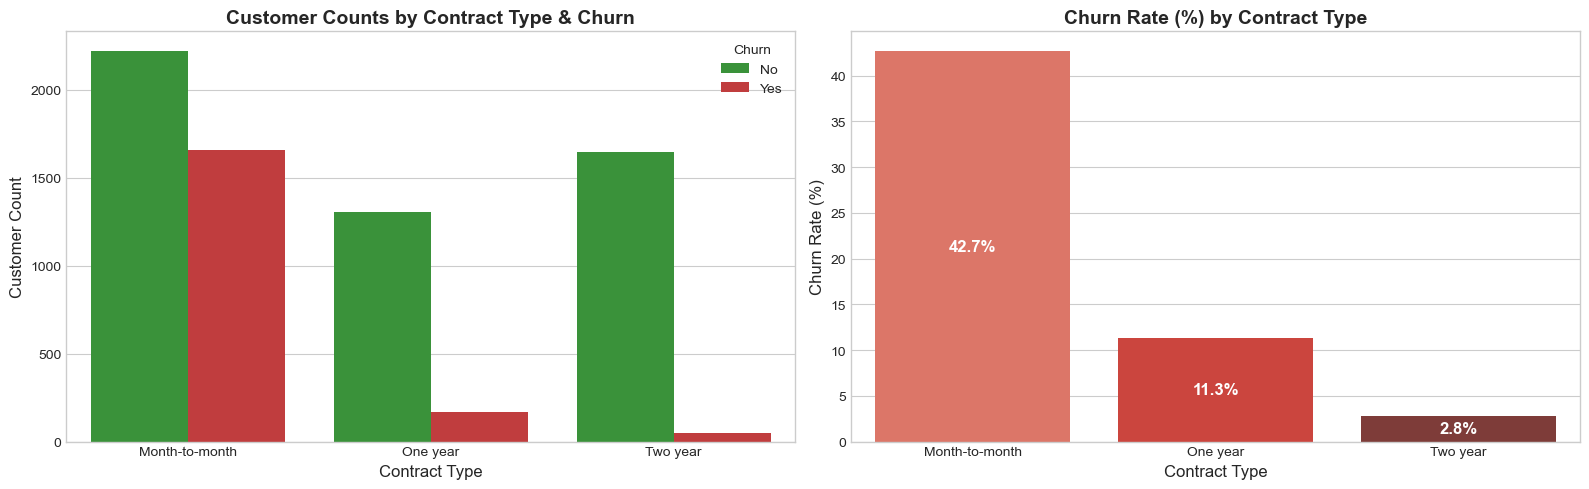

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Count Plot
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#2ca02c', '#d62728'], ax=ax[0])
ax[0].set_title('Customer Counts by Contract Type & Churn', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Contract Type', fontsize=12)
ax[0].set_ylabel('Customer Count', fontsize=12)

# Churn Rate Bar Plot
contract_churn = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=contract_churn, x='Contract', y='Churn', palette='Reds_d', ax=ax[1])
ax[1].set_title('Churn Rate (%) by Contract Type', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Contract Type', fontsize=12)
ax[1].set_ylabel('Churn Rate (%)', fontsize=12)
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Question 4: Does payment method appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\2619449704.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pay_churn, y='PaymentMethod', x='Churn', palette='Reds_d', ax=ax[1])


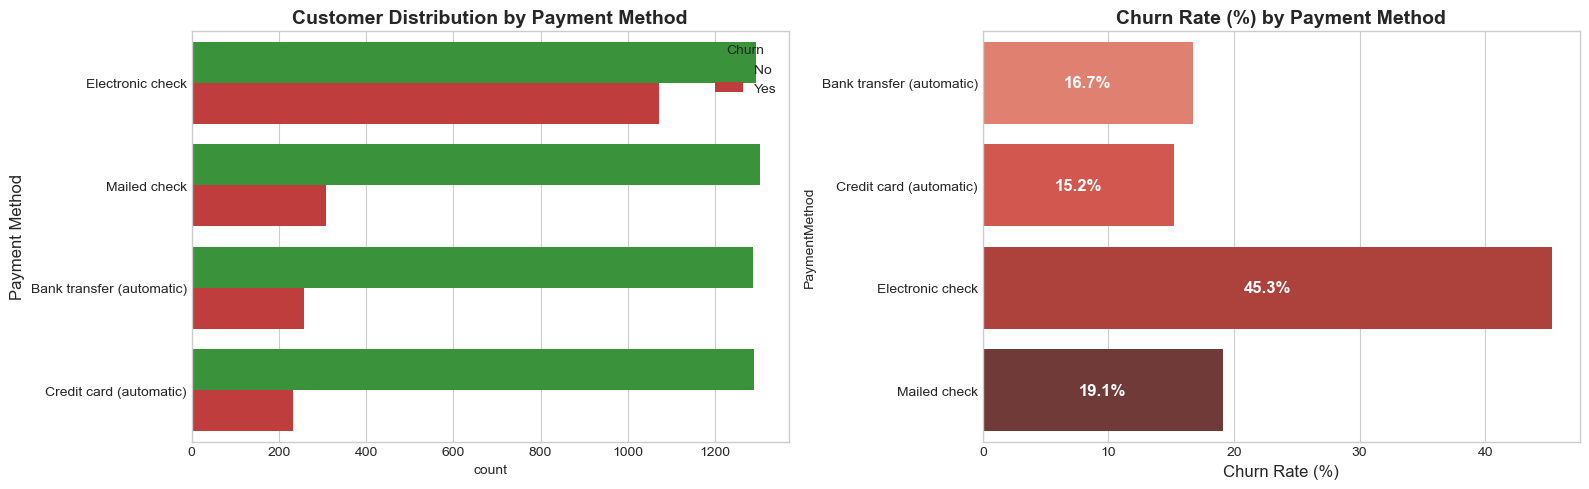

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Count Plot
sns.countplot(data=df, y='PaymentMethod', hue='Churn', palette=['#2ca02c', '#d62728'], ax=ax[0])
ax[0].set_title('Customer Distribution by Payment Method', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Payment Method', fontsize=12)

# Churn Rate Bar Plot
pay_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=pay_churn, y='PaymentMethod', x='Churn', palette='Reds_d', ax=ax[1])
ax[1].set_title('Churn Rate (%) by Payment Method', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Churn Rate (%)', fontsize=12)
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_width():.1f}%', (p.get_width() / 2, p.get_y() + p.get_height() / 2.),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Question 5: Does internet service type appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\351016759.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=net_churn, x='InternetService', y='Churn', palette='Reds_d', ax=ax[1])


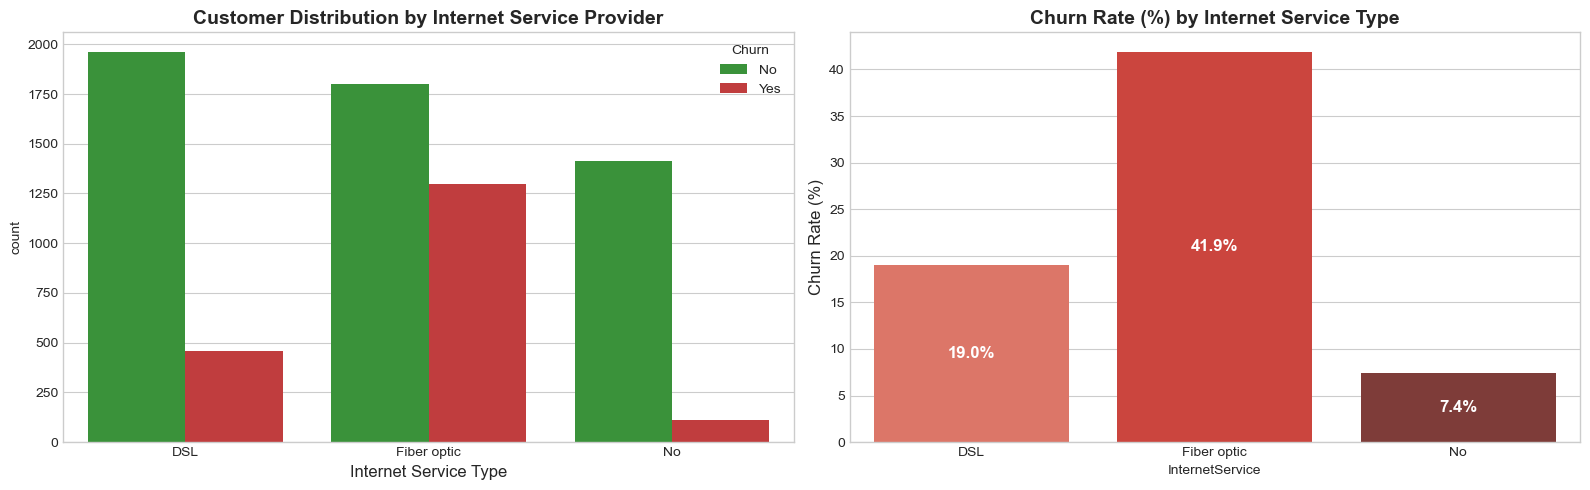

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Count Plot
sns.countplot(data=df, x='InternetService', hue='Churn', palette=['#2ca02c', '#d62728'], ax=ax[0])
ax[0].set_title('Customer Distribution by Internet Service Provider', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Internet Service Type', fontsize=12)

# Churn Rate Bar Plot
net_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=net_churn, x='InternetService', y='Churn', palette='Reds_d', ax=ax[1])
ax[1].set_title('Churn Rate (%) by Internet Service Type', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Churn Rate (%)', fontsize=12)
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Question 6 & 7: Do technical support and online security services appear related to churn?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\2715643081.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ts_churn, x='TechSupport', y='Churn', palette='Purples_r', ax=ax[0])
C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\2715643081.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sec_churn, x='OnlineSecurity', y='Churn', palette='Blues_r', ax=ax[1])


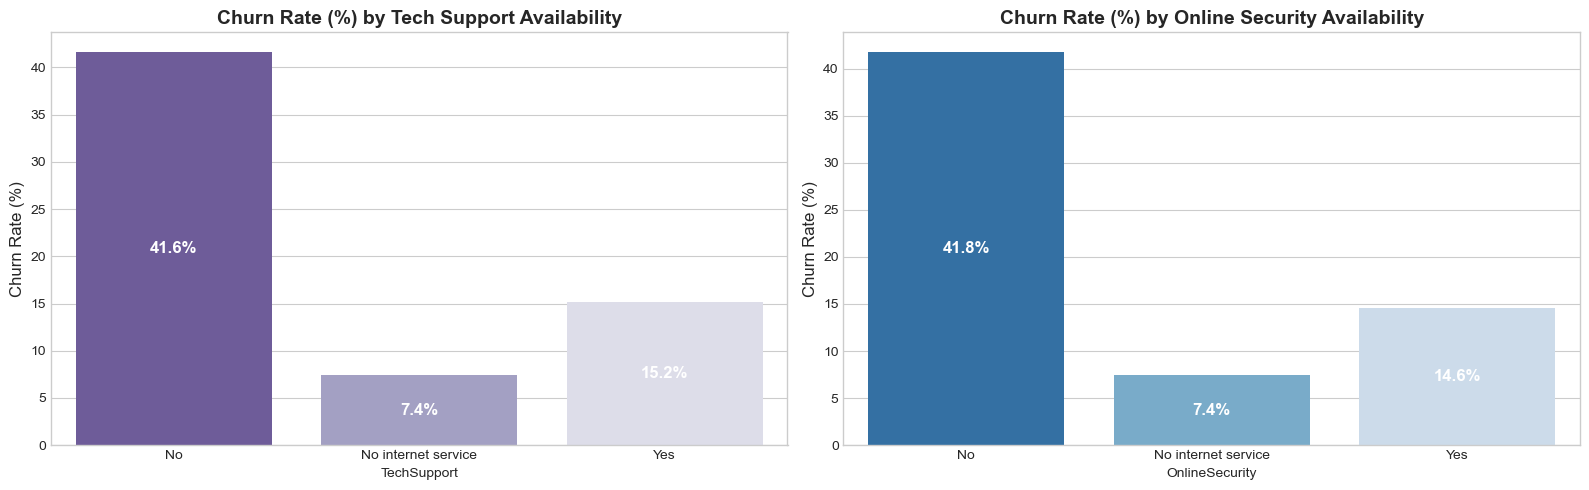

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Tech Support Churn Rate
ts_churn = df.groupby('TechSupport')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=ts_churn, x='TechSupport', y='Churn', palette='Purples_r', ax=ax[0])
ax[0].set_title('Churn Rate (%) by Tech Support Availability', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Churn Rate (%)', fontsize=12)
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Online Security Churn Rate
sec_churn = df.groupby('OnlineSecurity')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=sec_churn, x='OnlineSecurity', y='Churn', palette='Blues_r', ax=ax[1])
ax[1].set_title('Churn Rate (%) by Online Security Availability', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Churn Rate (%)', fontsize=12)
for p in ax[1].patches:
    ax[1].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Question 8: Are there differences in churn between customer segments?

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_37096\2865903632.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=senior_churn, x='SeniorCitizen', y='Churn', palette='Oranges_r', ax=ax[0])


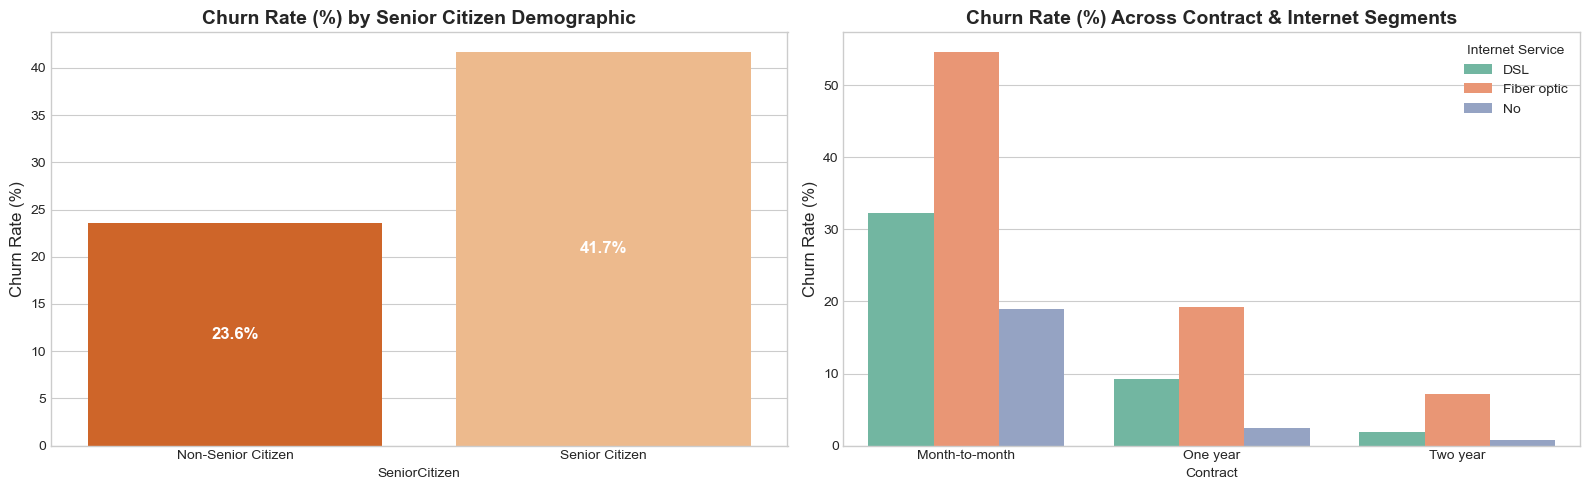

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Senior Citizen Churn Rate
senior_churn = df.groupby('SeniorCitizen')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
senior_churn['SeniorCitizen'] = senior_churn['SeniorCitizen'].map({0: 'Non-Senior Citizen', 1: 'Senior Citizen'})
sns.barplot(data=senior_churn, x='SeniorCitizen', y='Churn', palette='Oranges_r', ax=ax[0])
ax[0].set_title('Churn Rate (%) by Senior Citizen Demographic', fontsize=14, fontweight='bold')
ax[0].set_ylabel('Churn Rate (%)', fontsize=12)
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Segment interaction: Contract + InternetService
seg_churn = df.groupby(['Contract', 'InternetService'])['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
sns.barplot(data=seg_churn, x='Contract', y='Churn', hue='InternetService', palette='Set2', ax=ax[1])
ax[1].set_title('Churn Rate (%) Across Contract & Internet Segments', fontsize=14, fontweight='bold')
ax[1].set_ylabel('Churn Rate (%)', fontsize=12)
ax[1].legend(title='Internet Service')

plt.tight_layout()
plt.show()

## Business Insights

We synthesize our EDA findings into structured business observations, underlying causes, and actionable recommendations.

---  
### Insight 1 — Contract Commitment & Early Loyalty
- **Observation:** Customers on `Month-to-month` contracts suffer a massive **42.7% churn rate**, compared to **11.3%** for One-year contracts and **2.8%** for Two-year contracts.
- **Possible Explanation:** Month-to-month contracts have zero exit friction, making it seamless for dissatisfied customers to switch providers immediately.
- **Business Implication:** Implement targeted onboarding incentives (e.g., bill credits or free service add-ons) for month-to-month users who commit to 1-year or 2-year plans.

---  
### Insight 2 — Fiber Optic Customer Friction
- **Observation:** `Fiber optic` internet customers exhibit a **41.9% churn rate**, whereas `DSL` users churn at **19.0%** and non-internet users at **7.4%**.
- **Possible Explanation:** Fiber optic service is priced higher (averaging ~$91/month vs ~$58/month for DSL). Higher expectations regarding reliability and speed mean service outages or pricing spikes spark rapid customer defection.
- **Business Implication:** Audit fiber optic service quality, SLA performance, and pricing tiers to ensure competitive value delivery.

---  
### Insight 3 — Payment Method Friction (Electronic Check)
- **Observation:** Customers paying via `Electronic check` experience a **45.3% churn rate**, compared to **16.7% - 19.1%** for automated payment methods (Bank transfer, Credit card).
- **Possible Explanation:** Manual non-automatic payments increase monthly billing consciousness and payment friction, leading to active re-evaluations of monthly bills.
- **Business Implication:** Promote auto-pay signup incentives ($5 monthly discount for setting up automated credit card or bank payments).

---  
### Insight 4 — Crucial First-Year Window (Tenure < 12 Months)
- **Observation:** Median tenure for churned customers is only **10 months**, whereas retained customers have a median tenure of **38 months**.
- **Possible Explanation:** The onboarding and first-year lifecycle represent the most vulnerable phase of customer relationship.
- **Business Implication:** Deploy proactive customer success check-ins and loyalty touchpoints during months 1 through 6 to build long-term retention.

## Part 8: Feature Categorization

Before moving to feature engineering and modeling in Stage 3, we group features conceptually:

### 1. Numerical Features
- `tenure` (Discrete integer, months)
- `MonthlyCharges` (Continuous float, $)
- `TotalCharges` (Continuous float, $, following string-to-float cleaning)

### 2. Categorical Features
- **Demographic:** `gender`, `SeniorCitizen`, `Partner`, `Dependents`
- **Core Services:** `PhoneService`, `MultipleLines`, `InternetService`
- **Value-Added Add-ons:** `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`
- **Account & Financial:** `Contract`, `PaperlessBilling`, `PaymentMethod`

### 3. Potentially Unnecessary Features (Exclude from ML)
- `customerID`:
  - **Why Exclude:** `customerID` is a 100% unique alphanumeric key (`7,043` unique values across `7,043` rows). Including it in ML models would lead to severe overfitting, as the model would memorize arbitrary string patterns rather than learning generalizable churn signals.

## Stage 2 Summary

1. **Dataset Size:** 7,043 rows and 21 columns.
2. **Target Distribution:** Imbalanced distribution — 5,174 `No` (`73.46%`) vs. 1,869 `Yes` (`26.54%`).
3. **Important Numerical Features:** `tenure`, `MonthlyCharges`, `TotalCharges`.
4. **Important Categorical Features:** `Contract`, `InternetService`, `PaymentMethod`, `TechSupport`, `OnlineSecurity`.
5. **Missing-Data Issues:** `0` explicit `NaN` values, but **11 blank string entries (`" "`)** in `TotalCharges` corresponding to zero-tenure new customers.
6. **Duplicate-Data Issues:** `0` duplicate rows; all `7,043` `customerID` values are unique.
7. **Most Important Observations:** Highest churn rates occur among Month-to-Month contract holders (**42.7%**), Electronic Check payees (**45.3%**), Fiber Optic subscribers (**41.9%**), and short-tenure customers (< 12 months).
8. **Potentially Important Churn Predictors:** Contract length commitment, service tier selection, payment automation status, and presence of tech support / security add-ons.
9. **Key Questions for Model Building Stage:**
   - How to handle string-to-float conversion and imputation for `TotalCharges`.
   - How to handle class imbalance (e.g., scale_pos_weight in XGBoost, SMOTE, or threshold tuning).
   - How to encode categorical features (One-Hot Encoding vs Ordinal Encoding).
   - How to scale numerical features for distance-based or linear models.